In [ ]:
# import pandas as pd
# df = pd.read_csv('/Users/forough/Downloads/flashinfer2.csv')
# ls1 = []
# ls2 = []

# for row in df.itertuples(index=False):
#     txt = str(row.calls).replace(" ", "")
#     txtls = txt.split(",")
    
#     # Create temporary lists for the current row
#     current_row_ls1 = []
#     current_row_ls2 = []
    
#     prefix = str(row.prefix1).replace(" ", "")
    
#     for call in txtls:
#         current_row_ls1.append(f"{prefix}.{call}")
#         current_row_ls2.append(f"flashinfer.{call}")
    
#     # Append the WHOLE list as a single entry for this row
#     ls1.append(current_row_ls1)
#     ls2.append(current_row_ls2)

# df['fullcalls'] = ls1
# df['fullcalls2'] = ls2

# # Remove newlines from every string in the lists
# df['fullcalls'] = df['fullcalls'].apply(lambda x: [i.replace('\n', '').strip() for i in x])
# df['fullcalls2'] = df['fullcalls2'].apply(lambda x: [i.replace('\n', '').strip() for i in x])

# # Join the list elements into a single string separated by a comma and space
# df['fullcalls'] = df['fullcalls'].apply(lambda x: ", ".join(x))
# df['fullcalls2'] = df['fullcalls2'].apply(lambda x: ", ".join(x))

# def clean_and_quote(text):
#     # 1. Split and remove any existing quotes and whitespace
#     raw_items = [i.strip().replace('"', '') for i in str(text).split(',') if i.strip()]
    
#     # 2. Add quotes back using a simple string template
#     quoted_items = ['"{}"'.format(item) for item in raw_items]
    
#     return ", ".join(quoted_items)

# # Apply the function to the column
# df['fullcalls'] = df['fullcalls'].apply(clean_and_quote)

# # Merge everything into the final string
# final_output = df['fullcalls'].str.cat(sep=', ')

# print(final_output)

In [ ]:
# import pandas as pd
# df = pd.read_csv('/Users/forough/VScodeProjects/VScode_serving/dataset/code_content_processed_results/flashinfer_all_info.csv')

# import ast
# from collections import OrderedDict
# from typing import Dict, List, Optional, Tuple, Any


# def extract_models_by_framework(code: str) -> dict:
#     """
#     Analyze a Python script and extract model identifiers grouped by framework.

#     Returns a dict with exactly these keys (always present):
#       {
#         "vLLM": [],
#         "SGLang": [],
#         "TensorRT-LLM": [],
#         "LMDeploy": [],
#         "FlashInfer": [],
#         "Unknown": []
#       }

#     Notes / behavior:
#     - Uses AST parsing (no execution).
#     - Tracks simple string assignments and dict literals to resolve variables/kwargs.
#     - Handles positional args, keyword args, **kwargs, dict configs, argparse defaults, and
#       subprocess.* invocations (best-effort).
#     - If a value isn't a literal string, returns "VAR:<name>" or "EXPR:<short_expr>".
#     - Model identifiers are deduplicated per framework while preserving first-seen order.
#     """

#     # -------------------------
#     # Utilities: ordered unique
#     # -------------------------
#     def _ordered_unique_append(store: OrderedDict, s: str) -> None:
#         if s is None:
#             return
#         if s not in store:
#             store[s] = None

#     def _mk_output() -> Dict[str, List[str]]:
#         return {
#             "vLLM": [],
#             "SGLang": [],
#             "TensorRT-LLM": [],
#             "LMDeploy": [],
#             "FlashInfer": [],
#             "Unknown": [],
#         }

#     # -------------------------
#     # AST helpers
#     # -------------------------
#     def _safe_unparse(node: ast.AST) -> str:
#         try:
#             return ast.unparse(node)
#         except Exception:
#             return node.__class__.__name__

#     def _short_expr(node: ast.AST, limit: int = 80) -> str:
#         s = _safe_unparse(node)
#         s = " ".join(s.split())
#         return (s[:limit] + "...") if len(s) > limit else s

#     def _is_string_const(node: ast.AST) -> bool:
#         return isinstance(node, ast.Constant) and isinstance(node.value, str)

#     def _const_str(node: ast.AST) -> Optional[str]:
#         if _is_string_const(node):
#             return node.value
#         return None

#     def _normalize_framework_key(k: str) -> str:
#         # return one of the canonical keys
#         if k in ("vLLM", "SGLang", "TensorRT-LLM", "LMDeploy", "FlashInfer", "Unknown"):
#             return k
#         return "Unknown"

#     # -------------------------
#     # Heuristics for "model-ish"
#     # -------------------------
#     _MODELISH_TOKENS = (
#         "model", "checkpoint", "ckpt", "pretrained", "repo", "hf", "weights",
#         "engine", "artifact", "snapshot"
#     )
#     _PATHISH_HINTS = ("/", "./", "../", "s3://", "gs://", "hf://", "file://", "http://", "https://")

#     def _looks_like_model_identifier_string(s: str) -> bool:
#         # permissive, but avoids obvious false positives (tiny strings)
#         if not s or len(s.strip()) < 3:
#             return False
#         s2 = s.strip()
#         # Common model ids or paths/uris
#         if any(h in s2 for h in _PATHISH_HINTS):
#             return True
#         # HF-style repo id: org/name (at least one slash, no spaces)
#         if "/" in s2 and " " not in s2 and len(s2.split("/")[0]) > 1 and len(s2.split("/")[-1]) > 1:
#             return True
#         # Some checkpoints are named without slashes (rare); keep conservative
#         # (We will mostly pick these up through model-ish keys/call context anyway)
#         return False

#     def _is_modelish_key(key: str) -> bool:
#         k = (key or "").lower().replace("-", "_")
#         return any(tok in k for tok in _MODELISH_TOKENS)

#     # -------------------------
#     # Framework inference
#     # -------------------------
#     def _infer_framework_from_imports(imports: Dict[str, str]) -> Dict[str, bool]:
#         # imports: alias -> full module name
#         mods = set(imports.values()) | set(imports.keys())
#         mods_l = {m.lower() for m in mods if isinstance(m, str)}
#         return {
#             "vllm": any(m.startswith("vllm") or m == "vllm" for m in mods_l),
#             "sglang": any(m.startswith("sglang") or m == "sglang" or m.startswith("sgl") for m in mods_l),
#             "lmdeploy": any(m.startswith("lmdeploy") or m == "lmdeploy" for m in mods_l),
#             "tensorrt_llm": any(m.startswith("tensorrt_llm") or m == "tensorrt_llm" or "trtllm" in m for m in mods_l),
#             "flashinfer": any(m.startswith("flashinfer") or m == "flashinfer" for m in mods_l),
#         }

#     # Check call function path like vllm.LLM, sglang.Runtime, lmdeploy.pipeline, tensorrt_llm.Builder, etc.
#     def _get_call_qualname(node: ast.Call) -> str:
#         fn = node.func
#         if isinstance(fn, ast.Name):
#             return fn.id
#         if isinstance(fn, ast.Attribute):
#             parts = []
#             cur = fn
#             while isinstance(cur, ast.Attribute):
#                 parts.append(cur.attr)
#                 cur = cur.value
#             if isinstance(cur, ast.Name):
#                 parts.append(cur.id)
#             parts.reverse()
#             return ".".join(parts)
#         return _short_expr(fn)

#     def _framework_from_call(qualname: str, import_flags: Dict[str, bool]) -> Optional[str]:
#         q = qualname.lower()

#         # vLLM patterns
#         if "vllm" in q or q.endswith(".llm") or q.endswith(".asyncllmengine") or "engineargs" in q:
#             return "vLLM"
#         if import_flags.get("vllm"):
#             # common vLLM constructors invoked without module prefix via from-import
#             if qualname in {"LLM", "AsyncLLMEngine", "EngineArgs"}:
#                 return "vLLM"

#         # SGLang patterns
#         if "sglang" in q or q.startswith("sgl.") or "sgl" == q.split(".")[0] or "runtime" in q and import_flags.get("sglang"):
#             return "SGLang"
#         if import_flags.get("sglang"):
#             if qualname in {"Runtime", "Engine"}:
#                 return "SGLang"

#         # TensorRT-LLM patterns
#         if "tensorrt_llm" in q or "trtllm" in q:
#             return "TensorRT-LLM"
#         if import_flags.get("tensorrt_llm"):
#             if "builder" in q or "build" in q or "engine" in q or "executor" in q:
#                 # heuristic, but reasonable if tensorrt_llm imported
#                 return "TensorRT-LLM"

#         # LMDeploy patterns
#         if "lmdeploy" in q or q.endswith(".pipeline") or "turbomindengineconfig" in q or "pytorchengineconfig" in q:
#             return "LMDeploy"
#         if import_flags.get("lmdeploy"):
#             if qualname in {"pipeline", "TurbomindEngineConfig", "PytorchEngineConfig"}:
#                 return "LMDeploy"

#         # FlashInfer patterns
#         if "flashinfer" in q:
#             return "FlashInfer"
#         if import_flags.get("flashinfer"):
#             # FlashInfer usually called by module prefix; but keep fallback
#             if qualname.startswith("Batch") or "KVCache" in qualname:
#                 return "FlashInfer"

#         return None

#     # -------------------------
#     # Resolve values (best-effort)
#     # -------------------------
#     # Store simple resolvable environment: var -> value (string or dict of strings or list of strings)
#     env: Dict[str, Any] = {}

#     def _resolve_name(node: ast.AST) -> Optional[str]:
#         if isinstance(node, ast.Name):
#             return node.id
#         return None

#     def _resolve_str_like(node: ast.AST) -> str:
#         s = _const_str(node)
#         if s is not None:
#             return s
#         if isinstance(node, ast.JoinedStr):
#             return "EXPR:" + _short_expr(node)
#         if isinstance(node, ast.Name):
#             return f"VAR:{node.id}"
#         return "EXPR:" + _short_expr(node)

#     def _resolve_value(node: ast.AST) -> Any:
#         # Return: str | list | dict | placeholder string
#         if _is_string_const(node):
#             return node.value
#         if isinstance(node, ast.Name) and node.id in env:
#             return env[node.id]
#         if isinstance(node, ast.Dict):
#             d = {}
#             for k, v in zip(node.keys, node.values):
#                 if k is None:
#                     continue
#                 kk = _const_str(k) if _is_string_const(k) else _short_expr(k)
#                 d[kk] = _resolve_value(v)
#             return d
#         if isinstance(node, ast.List) or isinstance(node, ast.Tuple):
#             return [_resolve_value(elt) for elt in node.elts]
#         if isinstance(node, ast.Call):
#             # Could be dict(...) or list(...) or argparse.Namespace(...)
#             qn = _get_call_qualname(node).lower()
#             if qn == "dict":
#                 # dict(k=v, ...)
#                 d = {}
#                 for kw in node.keywords:
#                     if kw.arg is None:
#                         continue
#                     d[kw.arg] = _resolve_value(kw.value)
#                 return d
#             if qn in {"list", "tuple"}:
#                 return [_resolve_value(a) for a in node.args]
#         # fallback placeholder
#         return "EXPR:" + _short_expr(node)

#     def _merge_kwargs_into_dict(call_node: ast.Call) -> Dict[str, Any]:
#         merged: Dict[str, Any] = {}
#         # keyword args
#         for kw in call_node.keywords:
#             if kw.arg is None:
#                 # **kwargs
#                 if isinstance(kw.value, ast.Name) and kw.value.id in env and isinstance(env[kw.value.id], dict):
#                     for k, v in env[kw.value.id].items():
#                         merged[k] = v
#                 elif isinstance(kw.value, ast.Dict):
#                     dv = _resolve_value(kw.value)
#                     if isinstance(dv, dict):
#                         for k, v in dv.items():
#                             merged[k] = v
#                 else:
#                     merged["**"] = "EXPR:" + _short_expr(kw.value)
#             else:
#                 merged[kw.arg] = _resolve_value(kw.value)
#         return merged

#     # -------------------------
#     # Find model identifiers inside structures
#     # -------------------------
#     def _collect_models_from_obj(obj: Any, *, key_hint: Optional[str] = None) -> List[str]:
#         """
#         Collect candidate model identifiers from arbitrary resolved objects.

#         - If key_hint looks modelish, accept more aggressively.
#         - If string looks like path/HF-id, accept even without key hint.
#         """
#         out: List[str] = []

#         def rec(o: Any, kh: Optional[str]) -> None:
#             if isinstance(o, str):
#                 if o.startswith("VAR:") or o.startswith("EXPR:"):
#                     # placeholders are meaningful only if key/context suggests model
#                     if kh and _is_modelish_key(kh):
#                         out.append(o)
#                     return
#                 if (kh and _is_modelish_key(kh)) or _looks_like_model_identifier_string(o):
#                     out.append(o)
#                 return
#             if isinstance(o, dict):
#                 for kk, vv in o.items():
#                     rec(vv, kk if isinstance(kk, str) else kh)
#                 return
#             if isinstance(o, list):
#                 for vv in o:
#                     rec(vv, kh)
#                 return

#         rec(obj, key_hint)
#         return out

#     # -------------------------
#     # Parse imports to infer frameworks
#     # -------------------------
#     try:
#         tree = ast.parse(code)
#     except SyntaxError:
#         # Very broken script: fallback to minimal output
#         return _mk_output()

#     imports: Dict[str, str] = {}

#     for node in ast.walk(tree):
#         if isinstance(node, ast.Import):
#             for alias in node.names:
#                 name = alias.name
#                 asname = alias.asname or name.split(".")[0]
#                 imports[asname] = name
#         elif isinstance(node, ast.ImportFrom):
#             mod = node.module or ""
#             for alias in node.names:
#                 asname = alias.asname or alias.name
#                 imports[asname] = (mod + "." + alias.name).strip(".")

#     import_flags = _infer_framework_from_imports(imports)

#     # -------------------------
#     # Output stores (ordered unique per framework)
#     # -------------------------
#     out_store = {
#         "vLLM": OrderedDict(),
#         "SGLang": OrderedDict(),
#         "TensorRT-LLM": OrderedDict(),
#         "LMDeploy": OrderedDict(),
#         "FlashInfer": OrderedDict(),
#         "Unknown": OrderedDict(),
#     }

#     # -------------------------
#     # First pass: gather easy assignments (strings, dicts, lists)
#     # -------------------------
#     # This enables basic variable resolution for later calls.
#     for node in ast.walk(tree):
#         if isinstance(node, ast.Assign):
#             val = _resolve_value(node.value)
#             for tgt in node.targets:
#                 if isinstance(tgt, ast.Name):
#                     env[tgt.id] = val
#         elif isinstance(node, ast.AnnAssign):
#             if isinstance(node.target, ast.Name) and node.value is not None:
#                 env[node.target.id] = _resolve_value(node.value)

#     # -------------------------
#     # Second pass: inspect call sites + argparse + subprocess
#     # -------------------------
#     # 1) Call sites: try to infer framework and collect models from args/kwargs
#     for node in ast.walk(tree):
#         if isinstance(node, ast.Call):
#             qualname = _get_call_qualname(node)
#             fw = _framework_from_call(qualname, import_flags)

#             # Build a merged kw dict for model-ish keys and **kwargs resolution
#             kwdict = _merge_kwargs_into_dict(node)

#             # Collect candidates from keyword arguments with model-ish semantics
#             # (Do NOT rely only on a fixed list; use token heuristic.)
#             candidates: List[str] = []

#             for k, v in kwdict.items():
#                 if k == "**":
#                     continue
#                 # if key seems model-ish, collect from its value
#                 if isinstance(k, str) and _is_modelish_key(k):
#                     candidates.extend(_collect_models_from_obj(v, key_hint=k))

#             # Also consider positional first argument patterns for known constructors:
#             ql = qualname.lower()

#             # vLLM: LLM(model=...) typically, but sometimes LLM("repo-or-path")
#             if fw == "vLLM":
#                 if node.args:
#                     # only accept if it looks like a model identifier, otherwise placeholder
#                     v0 = _resolve_value(node.args[0])
#                     for s in _collect_models_from_obj(v0, key_hint="model"):
#                         candidates.append(s)

#             # LMDeploy: pipeline("model", ...) common
#             if fw == "LMDeploy":
#                 if node.args and (qualname == "pipeline" or qualname.lower().endswith(".pipeline")):
#                     v0 = _resolve_value(node.args[0])
#                     for s in _collect_models_from_obj(v0, key_hint="model"):
#                         candidates.append(s)

#             # SGLang: Engine(...) / Runtime(...) often uses model/model_path in kwargs;
#             # sometimes first arg is model
#             if fw == "SGLang":
#                 if node.args:
#                     v0 = _resolve_value(node.args[0])
#                     for s in _collect_models_from_obj(v0, key_hint="model"):
#                         candidates.append(s)

#             # TensorRT-LLM: engine building/loading may use engine_dir, model_dir, checkpoint, etc.
#             # Often passed as kwargs; positional arg sometimes used
#             if fw == "TensorRT-LLM":
#                 if node.args:
#                     v0 = _resolve_value(node.args[0])
#                     # Only accept if it looks like path/uri or placeholder under model context
#                     for s in _collect_models_from_obj(v0, key_hint="engine_dir"):
#                         candidates.append(s)

#             # FlashInfer itself doesn't load models; attribute only if model-like strings
#             # are present in the same call context (rare).
#             if fw == "FlashInfer":
#                 # Usually no model args. But if found via model-ish keys, keep them.
#                 pass

#             # If framework inferred, record there; else push to Unknown if candidates exist
#             if candidates:
#                 target_fw = fw if fw is not None else "Unknown"
#                 target_fw = _normalize_framework_key(target_fw)
#                 for s in candidates:
#                     _ordered_unique_append(out_store[target_fw], s)

#     # 2) argparse patterns: parser.add_argument(..., default="model") or choices=["model"]
#     for node in ast.walk(tree):
#         if isinstance(node, ast.Call):
#             qual = _get_call_qualname(node).lower()
#             if not (qual.endswith("add_argument") or qual == "add_argument"):
#                 continue

#             # Determine if this argument is likely the model argument by flag names
#             arg_flags = []
#             for a in node.args:
#                 if _is_string_const(a):
#                     arg_flags.append(a.value)

#             is_model_arg = any("model" in f.lower() or "checkpoint" in f.lower() or "ckpt" in f.lower() for f in arg_flags)

#             if not is_model_arg:
#                 continue

#             # Collect default / choices / metavar values that look like model identifiers
#             for kw in node.keywords:
#                 if kw.arg is None:
#                     continue
#                 k = kw.arg.lower()
#                 if k in ("default", "metavar"):
#                     v = _resolve_value(kw.value)
#                     for s in _collect_models_from_obj(v, key_hint="model"):
#                         _ordered_unique_append(out_store["Unknown"], s)
#                 if k == "choices":
#                     v = _resolve_value(kw.value)
#                     for s in _collect_models_from_obj(v, key_hint="model"):
#                         _ordered_unique_append(out_store["Unknown"], s)

#     # 3) subprocess patterns: subprocess.run([...]) / Popen([...]) / os.system("...")
#     def _collect_from_cli_list(cli_list: List[Any]) -> List[str]:
#         # Best-effort: look for tokens that appear after a model-ish flag or look like a model identifier.
#         out = []
#         model_flags = ("--model", "--model-name", "--model_name", "--model-path", "--model_path",
#                        "--model-dir", "--model_dir", "--checkpoint", "--ckpt", "--repo-id", "--repo_id",
#                        "--hf-model", "--hf_model", "--pretrained", "--engine-dir", "--engine_dir")
#         last_was_model_flag = False
#         for tok in cli_list:
#             if not isinstance(tok, str):
#                 continue
#             t = tok.strip()
#             tl = t.lower()
#             if tl in model_flags:
#                 last_was_model_flag = True
#                 continue
#             if last_was_model_flag:
#                 out.append(t if _looks_like_model_identifier_string(t) else t)
#                 last_was_model_flag = False
#                 continue
#             # positional model in CLI (common): lmdeploy serve ... <model>
#             if _looks_like_model_identifier_string(t):
#                 out.append(t)
#         return out

#     for node in ast.walk(tree):
#         # subprocess.run([...]) / subprocess.Popen([...])
#         if isinstance(node, ast.Call):
#             qn = _get_call_qualname(node).lower()

#             if qn in {"subprocess.run", "subprocess.popen", "subprocess.call", "run", "popen", "call"}:
#                 if not node.args:
#                     continue
#                 argv0 = _resolve_value(node.args[0])

#                 if isinstance(argv0, list):
#                     cli = []
#                     for item in argv0:
#                         if isinstance(item, str):
#                             cli.append(item)
#                         elif isinstance(item, dict):
#                             # ignore
#                             pass
#                         else:
#                             # placeholders
#                             if isinstance(item, str):
#                                 cli.append(item)
#                     found = _collect_from_cli_list(cli)
#                     for s in found:
#                         _ordered_unique_append(out_store["Unknown"], s)
#                 elif isinstance(argv0, str):
#                     # string command
#                     if _looks_like_model_identifier_string(argv0):
#                         _ordered_unique_append(out_store["Unknown"], argv0)
#                 else:
#                     _ordered_unique_append(out_store["Unknown"], "EXPR:" + _short_expr(node.args[0]))

#             # os.system("...")
#             if qn in {"os.system", "system"} and node.args:
#                 cmd = _resolve_value(node.args[0])
#                 if isinstance(cmd, str) and cmd and any(h in cmd for h in _PATHISH_HINTS):
#                     # naive extraction: split and collect pathish / hf-ish tokens
#                     toks = [t.strip(" ,\"'") for t in cmd.split()]
#                     for t in toks:
#                         if _looks_like_model_identifier_string(t):
#                             _ordered_unique_append(out_store["Unknown"], t)
#                 elif not isinstance(cmd, str):
#                     _ordered_unique_append(out_store["Unknown"], "EXPR:" + _short_expr(node.args[0]))

#     # -------------------------
#     # Final pass: If we detected FlashInfer usage but models were only found in Unknown,
#     # do NOT auto-attribute them to FlashInfer (FlashInfer doesn't load models).
#     # Keep as Unknown unless model appears in a call that we can attribute.
#     # -------------------------

#     # Build final output
#     result = _mk_output()
#     for k in result.keys():
#         result[k] = list(out_store[k].keys())

#     return result
# df["model"] = df["code"].apply(extract_models_by_framework)

# for _, row in df.iterrows():
#     print("model: ", row['model'])
#     print("\n")


In [ ]:
import pandas as pd
df = pd.read_csv(f'/Users/forough/VScodeProjects/VScode_serving/dataset/Extracted_models/lmdeploy_extracted_models.csv')

In [ ]:
df

,file_name,file_path,sha,url,repo_full_name,git_url,html_url,code,imports,imports_features,...,cleaned_extract_models_by_framework,vLLM,SGLang,TensorRT-LLM,LMDeploy,FlashInfer,Unknown,extract_all_model_identifiers,clean_extract_all_model_identifiers,merged_models
0,__init__.py,blowtorch/__init__.py,dc66e8625c10db9d3d0c2bc6d4880bcf78af6ab4,https://api.github.com/repositories/728460201/...,B0-B/blowtorch-transformer-api,https://api.github.com/repos/B0-B/blowtorch-tr...,https://github.com/B0-B/blowtorch-transformer-...,#!/usr/bin/env python3\n\n'''\nThis module was...,"_socket, gc, http, json, llama_cpp, os, pathli...","{'gc': [], 're': [], 'json': [], 'time': ['tim...",...,"{'vLLM': [], 'SGLang': [], 'TensorRT-LLM': [],...",[],[],[],[],[],[],"['Writer/palmyra-small', 'application/json', '/']",[],[]
1,vllm_rollout.py,verl/workers/rollout/vllm_rollout/vllm_rollout.py,abbf11310ebffec4bc00b8ac022b5558e25582fa,https://api.github.com/repositories/996502244/...,OpenMOSS/Embodied-Planner-R1,https://api.github.com/repos/OpenMOSS/Embodied...,https://github.com/OpenMOSS/Embodied-Planner-R...,# Copyright 2024 Bytedance Ltd. and/or its aff...,"contextlib, omegaconf, os, tensordict, torch, ...","{'typing': ['List'], 'contextlib': ['contextma...",...,"{'vLLM': [], 'SGLang': [], 'TensorRT-LLM': [],...",[],[],[],[],[],[],[],[],[]
2,cpu_offload_lmcache.py,vllm/examples/offline_inference/cpu_offload_lm...,8211629b24ecce19517649b68537a008293d3813,https://api.github.com/repositories/942185491/...,4ndrelim/copy-chat,https://api.github.com/repos/4ndrelim/copy-cha...,https://github.com/4ndrelim/copy-chat/blob/adc...,"# SPDX-License-Identifier: Apache-2.0\n""""""\nTh...","lmcache, os, time, vllm","{'os': [], 'time': [], 'lmcache': ['experiment...",...,"{'vLLM': ['Mistral-7B-Instruct'], 'SGLang': []...",['Mistral-7B-Instruct'],[],[],[],[],[],['mistralai/Mistral-7B-Instruct-v0.2'],['Mistral-7B-Instruct'],['Mistral-7B-Instruct']
3,test_llama_tp.py,tests/lora/test_llama_tp.py,3ac3b80ec827c967f9572fa56b5a417cbd7d8ea6,https://api.github.com/repositories/1018840181...,YingJZ/vllm,https://api.github.com/repos/YingJZ/vllm/git/b...,https://github.com/YingJZ/vllm/blob/44cb0413b0...,# SPDX-License-Identifier: Apache-2.0\n# SPDX-...,"subprocess, sys, typing, utils, vllm","{'subprocess': [], 'sys': [], 'typing': ['Unio...",...,"{'vLLM': ['Llama-2-7b'], 'SGLang': [], 'Tensor...",['Llama-2-7b'],[],[],[],[],['Llama-2-7b'],['meta-llama/Llama-2-7b-hf'],['Llama-2-7b'],['Llama-2-7b']
4,judge_cot.py,data_process/vllm_inference/judge_cot.py,cd82386034f677a81086d78f0582d6477d5c5c86,https://api.github.com/repositories/1015841281...,GAIR-NLP/MegaScience,https://api.github.com/repos/GAIR-NLP/MegaScie...,https://github.com/GAIR-NLP/MegaScience/blob/4...,import argparse\nimport json\nimport os\nfrom ...,"argparse, config, json, os, torch, tqdm, trans...","{'argparse': [], 'json': [], 'os': [], 'typing...",...,"{'vLLM': [], 'SGLang': [], 'TensorRT-LLM': [],...",[],[],[],[],[],[],[],[],[]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51789,process_text.py,pbd/pipelines/ocr_post_process/steps/process_t...,b3aa8ae5ab04b805b9696c144d9cb48211c6a4f1,https://api.github.com/repositories/938428945/...,Atharva-Phatak/palebluedot,https://api.github.com/repos/Atharva-Phatak/pa...,https://github.com/Atharva-Phatak/palebluedot/...,"""""""\nThis module provides functionality for ex...","dataclasses, pbd, time, torch, transformers, vllm","{'time': [], 'torch': [], 'transformers': ['Au...",...,"{'vLLM': [], 'SGLang': [], 'TensorRT-LLM': [],...",[],[],[],[],[],[],[],[],[]
51790,_llm.py,src/openllm/_llm.py,c12e31536556e0529e70ae6629cb16fc97f6573c,https://api.github.com/repositories/678488608/...,GutZuFusss/OpenLLM-CLJS,https://api.github.com/repos/GutZuFusss/OpenLL...,https://github.com/GutZuFusss/OpenLLM-CLJS/blo...,# Copyright 2023 BentoML Team. All rights rese...,"__future__, _configuration, _quantisation, _sc...","{'__future__': ['annotations'], 'collectio

In [ ]:
count = df["merged_models"].apply(lambda x: isinstance(x, list) and len(x) > 0).sum()
print("Count of non-empty lists in column 'merged_models':", count)

Count of non-empty lists in column 'merged_models': 0


In [ ]:
import pandas as pd
df = pd.read_csv(f'/Users/forough/VScodeProjects/VScode_serving/dataset/repo_info/lightllm/info_lightllm_chunk_1.csv')
df

In [ ]:
print(df.columns)

In [ ]:
df.head()

In [ ]:
# backup:
    # # Sglang variable and parameters name:
    # #  for example, for speculative decoding we have : sgl.Engine(speculative_algorithm="eagle"), sgl.Engine(speculative_draft_model_path="TinyLlama/TinyLlama-1.1B"), sgl.Engine(speculative_num_steps=4)
    # # Thus, in the following dictionary we have a key and value like: "speculative decoding": ["speculative_algorithm", "speculative_draft_model_path", "speculative_num_steps"]

    # vllm_parameters = {"Speculative decoding": ["speculative_config"],
    #                 "Early existing":["early_stopping"],
    #                 "Cascade inference":["disable_cascade_attn"],
    #                 "Paged Attention":["attention_kernels","paged_attention_kernel"],
    #                 "Continuous batching":["max_num_batched_tokens","batch_size"],
    #                 "Quantization":["quantization","QuantizeConfig","GPTQModifier","SmoothQuantModifier","QuantizationModifier"],
    #                 "Chunked prefill":["enable_chunked_prefill"],
    #                 "parallelism":["PARTITION_SIZE","tensor_parallel_size","pipeline-parallel-size"],
    #                 "Prefix caching":["enable_prefix_caching"],
    #                 "Multi-LoRA":["enable_lora","lora_request"]}

    # sglan_parameters = {"RadixAttention":["disable_radix_cache","radix_eviction_policy"],
    #         "zero-overhead CPU scheduler": ["schedule_policy", "schedule_conservativeness", "enable_priority_scheduling", "schedule_low_priority_values_first", "priority_scheduling_preemption_threshold", "num_continuous_decode_steps", "scheduler_recv_interval", "enable_two_batch_overlap", "enable_single_batch_overlap", "tbo_token_distribution_threshold"],
    #         "prefill-decode disaggregation": ["disaggregation_mode", "disaggregation_transfer_backend", "disaggregation_bootstrap_port", "disaggregation_decode_tp", "disaggregation_decode_dp", "disaggregation_prefill_pp", "disaggregation_ib_device", "disaggregation_decode_enable_offload_kvcache", "disaggregation_decode_polling_interval"],
    #         "speculative decoding": ["speculative_algorithm", "speculative_draft_model_path", "speculative_num_steps", "speculative_eagle_topk", "speculative_eagle_topk_scale", "speculative_accept_threshold_single", "speculative_accept_threshold_acc", "speculative_token_map", "speculative_num_draft_tokens"],
    #         "continuous batching": ["max_running_requests", "max_queued_requests", "max_total_tokens", "num_continuous_decode_steps", "schedule_conservativeness", "disable_overlap_schedule", "enable_two_batch_overlap", "enable_single_batch_overlap", "tbo_token_distribution_threshold", "max_prefill_tokens", "chunked_prefill_size", "schedule_policy", "scheduler_recv_interval", "schedule_low_priority_values_first", "enable_priority_scheduling", "priority_scheduling_preemption_threshold"],
    #         "paged attention": ["page_size"],
    #         "tensor parallelism": ["tensor_parallel_size"],
    #         "pipeline parallelism": ["pipeline_parallel_size"],
    #         "expert parallelism": ["ep_size", "moe_mode", "moe_group_by", "moe_num_experts", "moe_top_k"],
    #         "data parallelism": ["dp_size"],
    #         "chunked prefill": ["chunked_prefill_size", "max_prefill_tokens"],
    #         "quantization": ["quantization"],
    #         "multi-LoRA batching": ["enable_lora", "lora_model_dir", "max_lora_models", "max_lora_rank", "lora_dtype"]}

    # openllm_parameters = {"quantization": ["quantize"],
    #                     "tensor parallelism": ["tensor_parallel_size"],
    #                     "pipeline parallelism": ["pipeline_parallel_size"]}
            
    # tensorrt_llm_parameters = {"In-Flight Batching": ["dynamic_batch", "batching_type", "max_batch_size"],
    #                         "Paged Attention": ["kv_cache_config"],
    #                         "Multi-GPU": ["tensor_parallel_size", "moe_expert_parallel_size", "moe_tensor_parallel_size"],
    #                         "quantization": ["quant_config"],
    #                         "Speculative Decoding": ["speculative_decoding_mode", "speculative_config"],
    #                         "KV Cache Management": ["kv_cache_config", "cache_transceiver_config", "kv_cache_retention_config"],
    #                         "Chunked Prefill": ["enable_chunked_prefill"],
    #                         "LoRA Support": ["enable_lora", "lora_config", "max_lora_rank"],
    #                         "Guided Decoding": ["guided_decoding_backend"],
    #                         "Disaggregated Serving": ["disaggregated_params"]}

    # lmdeploy_parameters = {"persistent batch": ["max_batch_size", "max_prefill_token_num", "max_prefill_iters", "session_len", "prefill_interval"],
    #                     "KV-cache": ["cache_max_entry_count", "enable_prefix_caching", "quant_policy", "eviction_type", "cache_chunk_size", "cache_block_seq_len"],
    #                     "dynamic split": ["max_prefill_token_num", "num_tokens_per_iter", "max_prefill_iters", "prefill_interval"],
    #                     "tensor parallelism": ["tp", "attn_tp_size", "mlp_tp_size", "moe_tp_size"],
    #                     "high-performance CUDA kernels": ["dtype", "use_logn_attn", "communicator", "devices", "device_type"],
    #                     "Quantization": ["model_format", "quant_policy"],
    #                     "Automatic Prefix Caching": ["enable_prefix_caching"]}


In [4]:
import pandas as pd

In [6]:
file_path = f'/Users/forough/VScodeProjects/Vscode_serving/dataset/code_content_processed_results/vllm_all_info.csv'
df = pd.read_csv(file_path).sort_values(by="repo_full_name").reset_index(drop=True)


In [7]:
print(df.columns)

Index(['file_name', 'file_path', 'sha', 'url', 'repo_full_name', 'git_url',
       'html_url', 'code', 'imports', 'imports_features', 'imports_as',
       'filtered_imports_as', 'filtered_imports_features', 'filtered_imports',
       'params', 'function'],
      dtype='object')


In [8]:
df

,file_name,file_path,sha,url,repo_full_name,git_url,html_url,code,imports,imports_features,imports_as,filtered_imports_as,filtered_imports_features,filtered_imports,params,function
0,test_vstar_r3.py,src/eval/test_vstar_r3.py,59afb66b67110bf2f46bdce6d6ac3e4b34833e3a,https://api.github.com/repositories/1034583614...,0001Henry/VLM-R3,https://api.github.com/repos/0001Henry/VLM-R3/...,https://github.com/0001Henry/VLM-R3/blob/b9a14...,from datetime import datetime\nfrom openai imp...,"PIL, collections, datetime, json, numpy, opena...","{'datetime': ['datetime'], 'openai': ['OpenAI'...",{'numpy': 'np'},{},"{'vllm': ['LLM', 'SamplingParams']}",vllm,"{'LLM': {'model': 'MODEL_PATH', 'device': 'VLL...",LLM
1,vllm_grpo_trainer_vanilla_rl.py,src/r1-v/src/open_r1/trainer/vllm_grpo_trainer...,6b5347370253271b95a90ede8e7ffe57fd224538,https://api.github.com/repositories/1034583614...,0001Henry/VLM-R3,https://api.github.com/repos/0001Henry/VLM-R3/...,https://github.com/0001Henry/VLM-R3/blob/b9a14...,# Copyright 2025 The HuggingFace Team. All rig...,"PIL, accelerate, collections, copy, datasets, ...","{'tqdm': ['tqdm'], 'PIL': ['Image'], 'json': [...","{'numpy': 'np', 'torch.multiprocessing': 'mp',...",{},"{'vllm': ['LLM', 'SamplingParams']}",vllm,{'SamplingParams': {'temperature': 'self.tempe...,SamplingParams
2,vllm_grpo_trainer_modified.py,src/r1-v/src/open_r1/trainer/vllm_grpo_trainer...,ed69382735a4a4a45037b729d6ed7bff5851bd2f,https://api.github.com/repositories/1034583614...,0001Henry/VLM-R3,https://api.github.com/repos/0001Henry/VLM-R3/...,https://github.com/0001Henry/VLM-R3/blob/b9a14...,# Copyright 2025 The HuggingFace Team. All rig...,"accelerate, collections, copy, datasets, os, p...","{'os': [], 'textwrap': [], 'collections': ['de...",{'torch.nn': 'nn'},{},"{'vllm': ['LLM', 'SamplingParams']}",vllm,{'SamplingParams': {'temperature': 'args.tempe...,SamplingParams
3,vllm.py,src/eval/vllm.py,790e9cfcefae36b2c2fe6f145e0e643579f67b6c,https://api.github.com/repositories/1034583614...,0001Henry/VLM-R3,https://api.github.com/repos/0001Henry/VLM-R3/...,https://github.com/0001Henry/VLM-R3/blob/b9a14...,from tqdm import tqdm\nfrom PIL import Image\n...,"PIL, accelerate, asyncio, base64, concurrent, ...","{'tqdm': ['tqdm'], 'PIL': ['Image'], 'json': [...","{'numpy': 'np', 'torch.multiprocessing': 'mp',...",{},"{'vllm': ['LLM', 'SamplingParams']}",vllm,{'SamplingParams': {'temperature': 'self.tempe...,SamplingParams
4,vllm_grpo_trainer.py,src/r1-v/src/open_r1/trainer/vllm_grpo_trainer.py,21404d5b8bb7c0427fd6557bd4633eb177dc5d22,https://api.github.com/repositories/1034583614...,0001Henry/VLM-R3,https://api.github.com/repos/0001Henry/VLM-R3/...,https://github.com/0001Henry/VLM-R3/blob/b9a14...,# Copyright 2025 The HuggingFace Team. All rig...,"accelerate, collections, copy, datasets, os, p...","{'os': [], 'textwrap': [], 'collections': ['de...",{'torch.nn': 'nn'},{},"{'vllm': ['LLM', 'SamplingParams']}",vllm,{'SamplingParams': {'temperature': 'args.tempe...,SamplingParams
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27492,cache_short_long_cot_model.py,src/train_dynamic_lora/cache_short_long_cot_mo...,59472496a58eea4c2dc0ca5bda68cccd0b6e4b4f,https://api.github.com/repositories/990518940/...,zzli2022/TLDR,https://api.github.com/repos/zzli2022/TLDR/git...,https://github.com/zzli2022/TLDR/blob/a4608886...,"import argparse\nimport json, os\nfrom vllm im...","argparse, contextlib, gc, json, math_verify, o...","{'argparse': [], 'json': [], 'os': [], 'vllm':...",{},{},"{'vllm': ['LLM', 'SamplingParams', 'distribute...",vllm,"{'LLM': {'model': 'args.model_path', 'enable_s...",LLM
27493,response_rewrite.py,scripts/response_rewrite.py,bc265ffed0f551963216d3c18f2b2ba788c50b03,https://api.github.com/repositories/990518940/...,zzli2022/TLDR,https://api.github.com/repos/zzli2022/TLDR/git...,https://github.com/zzli2022/TLDR/blob/a4608886...,import argparse\nimport json\nimport os\nimpor...,"argparse, json, os, random, skythought_evals, ..."

In [3]:
import pickle

target_col_ = "repository_intent"
summary = "sentence"

with open(f"topic_modeling_results/{target_col_}_{summary}.pkl", "rb") as f:
    evaluation_results = pickle.load(f)
evaluation_results
    

{'original_results':       dataset                 config_id       topic_stage ngram_range  min_df  \
 0    original  original__(1, 1)__1__0.7  initial_detected      (1, 1)       1   
 1    original  original__(1, 1)__1__0.7           reduced      (1, 1)       1   
 2    original  original__(1, 1)__1__0.7           reduced      (1, 1)       1   
 3    original  original__(1, 1)__1__0.7           reduced      (1, 1)       1   
 4    original  original__(1, 1)__1__0.7           reduced      (1, 1)       1   
 ..        ...                       ...               ...         ...     ...   
 157  original  original__(1, 3)__3__0.9           reduced      (1, 3)       3   
 158  original  original__(1, 3)__3__0.9           reduced      (1, 3)       3   
 159  original  original__(1, 3)__3__0.9           reduced      (1, 3)       3   
 160  original  original__(1, 3)__3__0.9           reduced      (1, 3)       3   
 161  original  original__(1, 3)__3__0.9           reduced      (1, 3)       3

In [6]:
from utils import *

%load_ext autoreload
%autoreload 2

import utils
best_output = select_and_print_best_config(evaluation_results)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload

BEST RESULT BASED ON 0.5 * NORMALIZED CV + 0.5 * NORMALIZED U_MASS

Metrics:
dataset: slightly_preprocessed
topic_stage: initial_detected
ngram_range: (1, 3)
min_df: 1
max_df: 0.7
initial_k_detected: 2.0
k_requested: 2
k_actual: 2.0
cv_coherence: 0.4607302157398685
umass_coherence: -3.197327754961317
cv_norm: 0.8246556446608186
umass_norm: 1.0
combined_score: 0.9123278223304093
n_noise: 2.0
noise_ratio: 0.0038240917782026767
error: None

Number of samples in each topic:
Topic 0: 468 samples
Topic 1: 53 samples

Keywords in each topic:
Topic 0: ['ai', 'inference', 'language', 'aims', 'open', 'serving', 'source', 'training', 'code', 'open source']
Topic 1: ['reinforcement', 'reinforcement learning', 'learning', 'training', 'reasoning', 'rl', 'multi', 'learning techniques', 'reinforcement learning techniques', 'efficient']


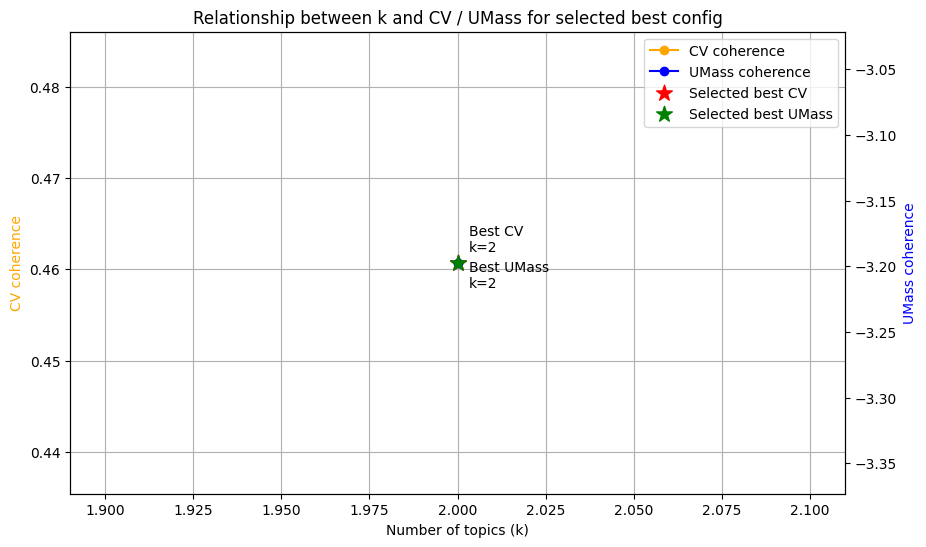

In [7]:
plot_df = plot_k_vs_cv_umass_for_best_config(best_output)

In [ ]:
def assign_best_topics_to_cleaned_df(cleaned_df, results, target_column, best_output=None):
    import pandas as pd
    import numpy as np

    df_out = cleaned_df.copy()

    # ------------------------------------------------------------------
    # Required columns
    # ------------------------------------------------------------------
    slight_col = f"{target_column}_slightly_preprocessed"
    full_col   = f"{target_column}_fully_preprocessed"

    required_cols = [target_column, slight_col, full_col]
    missing_cols = [c for c in required_cols if c not in df_out.columns]
    if missing_cols:
        raise ValueError(
            f"Missing required columns in cleaned_df: {missing_cols}"
        )

    # ------------------------------------------------------------------
    # Get best config if not already provided
    # ------------------------------------------------------------------
    if best_output is None:
        best_output = select_and_print_best_config(results)

    if best_output is None or best_output.get("best_result") is None:
        raise ValueError("Could not find a valid best result from select_and_print_best_config(results).")

    best_row = best_output["best_result"]
    run_registry = results["run_registry"]

    run_key = best_row["run_key"]
    if pd.isna(run_key) or run_key not in run_registry:
        raise ValueError(f"Best run_key '{run_key}' is missing from results['run_registry'].")

    best_run = run_registry[run_key]
    best_model = best_run["model"]
    best_dataset = best_row["dataset"]
    best_stage = best_row["topic_stage"]

    # ------------------------------------------------------------------
    # Decide which text column was used by the winning configuration
    # ------------------------------------------------------------------
    dataset_to_col = {
        "original": target_column,
        "slightly_preprocessed": slight_col,
        "fully_preprocessed": full_col
    }

    if best_dataset not in dataset_to_col:
        raise ValueError(f"Unknown dataset value in best_result: {best_dataset}")

    selected_text_col = dataset_to_col[best_dataset]

    # ------------------------------------------------------------------
    # Create output columns
    # Store topic IDs there
    # ------------------------------------------------------------------
    df_out["initial_k_detected_topic"] = pd.Series(pd.NA, index=df_out.index, dtype="Int64")
    df_out["detected_k_reduced"] = pd.Series(pd.NA, index=df_out.index, dtype="Int64")

    # ------------------------------------------------------------------
    # Match the same filtering logic used in _fit_and_evaluate_one(...)
    # It used:
    # texts = pd.Series(texts).fillna("").astype(str)
    # texts = texts[texts.str.strip() != ""].reset_index(drop=True)
    # ------------------------------------------------------------------
    selected_texts = df_out[selected_text_col].fillna("").astype(str)
    valid_mask = selected_texts.str.strip() != ""
    valid_index = df_out.index[valid_mask]
    valid_docs = selected_texts.loc[valid_mask].tolist()

    # ------------------------------------------------------------------
    # Use stored topics if length matches training docs exactly;
    # otherwise fall back to transform(...)
    # ------------------------------------------------------------------
    assigned_topics = None

    if hasattr(best_model, "topics_") and best_model.topics_ is not None:
        stored_topics = list(best_model.topics_)
        if len(stored_topics) == len(valid_docs):
            assigned_topics = stored_topics

    if assigned_topics is None:
        assigned_topics, _ = best_model.transform(valid_docs)

    # ------------------------------------------------------------------
    # Assign only one column depending on the winning stage
    # ------------------------------------------------------------------
    assigned_topics_series = pd.Series(assigned_topics, index=valid_index, dtype="Int64")

    if best_stage == "initial_detected":
        df_out.loc[valid_index, "initial_k_detected_topic"] = assigned_topics_series
        # detected_k_reduced stays empty

    elif best_stage == "reduced":
        df_out.loc[valid_index, "detected_k_reduced"] = assigned_topics_series
        # initial_k_detected_topic stays empty

    else:
        raise ValueError(
            f"Best result topic_stage must be 'initial_detected' or 'reduced', got: {best_stage}"
        )

    # ------------------------------------------------------------------
    # Optional helpful metadata
    # ------------------------------------------------------------------
    topic_keyword_map = {}
    topic_info = best_model.get_topic_info()

    if topic_info is not None and not topic_info.empty:
        for tid in topic_info["Topic"].tolist():
            if tid == -1:
                topic_keyword_map[tid] = ["noise"]
            else:
                words_scores = best_model.get_topic(tid)
                if words_scores is None:
                    topic_keyword_map[tid] = []
                else:
                    topic_keyword_map[tid] = [w for w, _ in words_scores]

    info = {
        "best_result": best_row,
        "selected_text_column": selected_text_col,
        "selected_dataset": best_dataset,
        "selected_stage": best_stage,
        "run_key": run_key,
        "topic_keyword_map": topic_keyword_map
    }

    return df_out, info

In [ ]:
best_output = select_and_print_best_config(results)

cleaned_df_with_topics, topic_info = assign_best_topics_to_cleaned_df(
    cleaned_df=cleaned_df,
    results=results,
    target_column=target_column,
    best_output=best_output
)